# Estado del arte: herramientas de pruebas de resultados, bibliotecas conformes, explicadores y bibliotecas de equidad

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 01 a 07 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- nombrar las herramientas abiertas que ofrecen pruebas de resultados, monitoreo sin etiquetas, predicción conforme, explicadores y métricas de equidad, decir bajo qué licencia puede usarlas un producto de este tipo, y decir qué pruebas de las instrucciones del BCE ninguna implementa;
- comparar el cuantil conforme dividido del motor con el que devuelve el paquete MAPIE 1.5.0, corrido, y contar en una grilla con qué frecuencia devuelven estadísticos de orden distintos;
- comprobar las pruebas z de dos proporciones y de Fisher del motor contra identidades independientes de SciPy, y sus tasas de selección, su diferencia de paridad y su razón de paridad contra fairlearn 0.15.0 corriendo sobre los conteos de HMDA versionados;
- decir qué partes de este cuaderno se corrieron y cuáles no pudieron correrse: NannyML y SHAP no están en el entorno de este cuaderno, así que sus resultados no se reproducen aquí.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 mapie==1.5.0 fairlearn==0.15.0 scikit-learn==1.9.1
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import inference, metrics
from riskvalidation.ml import conformal
from scipy import stats

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "mapie", "fairlearn", "scikit-learn"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
mapie 1.5.0
fairlearn 0.15.0
scikit-learn 1.9.1


## Datos

- **El catálogo del motor** de pruebas de validación (`riskvalidation.catalogue()`), para contar lo que el motor implementa para validación de aprendizaje automático y de equidad.
- **El tamaño de calibración versionado del caso C20** (`data/derived/C20/fed-shift.json`): las ventanas conformes de la variante de desplazamiento de la Reserva Federal usan una ventana de calibración de 1.471 empresas. El cuaderno usa solo ese número, y saca puntajes aleatorios de ese tamaño.
- **Los conteos de HMDA versionados del caso C21** (`data/derived/C21/pair-2018-19.json`): el conteo favorable y el tamaño de cada grupo de raza de Delaware 2018, para comparar las pruebas de dos tasas del motor con identidades independientes.

No hace falta ningún dato crudo nuevo. (Los puntajes del recorrido conforme son sorteos aleatorios del tamaño versionado con semilla fija; no se genera nada más.) Ambos documentos se leen por sus números y por la versión del motor que los horneó, impresa a continuación.

In [2]:
# Contar las pruebas de ML y de equidad del motor y leer la versión del motor y los tamaños de los dos documentos versionados
catalogue = rv.catalogue()
by_family = {}
for spec in catalogue:
    by_family[spec.family] = by_family.get(spec.family, 0) + 1
print("pruebas en el catálogo:", len(catalogue), "| ml:", by_family["ml"], "| fairness:", by_family["fairness"])
fed = json.loads((ROOT / "data" / "derived" / "C20" / "fed-shift.json").read_text(encoding="utf-8"))
hmda = json.loads((ROOT / "data" / "derived" / "C21" / "pair-2018-19.json").read_text(encoding="utf-8"))
print("C20 horneado con riskvalidation", fed["provenance"]["riskvalidation_version"], "| C21", hmda["provenance"]["riskvalidation_version"])
n_cal = next(t for t in fed["tests"] if t["test_id"] == "ml.conformal_coverage")["extras"]["n_cal"]
print("ventana de calibración versionada:", n_cal)

pruebas en el catálogo: 129 | ml: 13 | fairness: 12
C20 horneado con riskvalidation 0.8.1 | C21 0.8.1
ventana de calibración versionada: 1471


## Método

La comparación tiene dos reglas. **Reproducir donde un referente fijado lo permite**: se corre el paquete de referencia, una implementación independiente o una identidad que vale entre dos fórmulas, y se informa la diferencia con su tolerancia y la fuente de la diferencia. **Decir lo que no se corrió**: una biblioteca que no está en el entorno del cuaderno no se importa, y su resultado no se reproduce. MAPIE 1.5.0, fairlearn 0.15.0 y el scikit-learn 1.9.1 que ambos necesitan están instalados aquí con versiones exactas; NannyML y SHAP no.

### El cuantil conforme dividido contra MAPIE

Para $n$ puntajes de calibración $s_{(1)} \le \dots \le s_{(n)}$ el cuantil conforme exacto es el estadístico de orden $s_{(k)}$ con $k = \lceil (n+1)(1-\alpha) \rceil$ (cuaderno 04). El motor calcula $k$ sobre el decimal exacto de $\alpha$. La referencia es el paquete mismo, corrido: el `SplitConformalRegressor` de MAPIE 1.5.0 con un estimador ya ajustado que predice siempre 0, de modo que los residuos absolutos que conformaliza son los puntajes de calibración y el extremo superior de su intervalo alrededor de esa predicción es su cuantil. Junto a él se muestran otras dos reglas. La primera es la llamada de NumPy

$$\hat q_{\text{NumPy}} = \texttt{np.quantile}\bigl(s,\; (n+1)(1-\alpha)/n,\; \texttt{method="higher"}\bigr)$$

(el nivel acotado a 1), que una lectura anterior del código de MAPIE atribuyó al paquete y que la documentación del motor señala como no referencia: puede devolver $s_{(k+1)}$ donde la regla exacta devuelve $s_{(k)}$. La segunda es la regla ingenua en flotantes, $s_{(\lceil (n+1)(1-\alpha) \rceil)}$ con el producto tomado en flotantes.

La celda siguiente saca puntajes aleatorios del tamaño de calibración versionado (con semilla; el archivo versionado entrega solo el tamaño), aplica las cuatro reglas con $\alpha = 0{,}1$ e imprime el estadístico de orden que devuelve cada una. Luego recorre la grilla $n = 5, \dots, 399$ y $\alpha = 0{,}01, \dots, 0{,}99$ y cuenta los pares en que cada regla difiere del motor. MAPIE rechaza un par cuando falla su propia verificación, que su mensaje de error enuncia como que el número de puntajes sea menor que $1/\alpha$ o que $1/(1-\alpha)$; la celda cuenta esos rechazos aparte de las diferencias y comprueba que todo par que MAPIE rechaza y el motor responde cumple esa condición enunciada. La tolerancia es la igualdad exacta del puntaje devuelto: toda regla devuelve uno de los puntajes de calibración, así que una diferencia es un estadístico de orden distinto, nunca un redondeo.

In [3]:
# Las cuatro reglas al tamaño de calibración versionado, luego un recorrido de grilla de cuántas veces cada una difiere del motor
import collections

from mapie.regression import SplitConformalRegressor
from sklearn.dummy import DummyRegressor


def mapie_quantile(scores, alpha):
    """El extremo superior del intervalo que MAPIE 1.5.0 construye alrededor de una predicción de 0 cuando `scores` son sus residuos absolutos; None cuando MAPIE rechaza el par (alfa, n)."""
    estimator = DummyRegressor(strategy="constant", constant=0.0).fit(np.zeros((2, 1)), np.zeros(2))
    splitter = SplitConformalRegressor(estimator=estimator, confidence_level=1 - alpha, prefit=True)
    splitter.conformalize(np.zeros((scores.size, 1)), scores)
    try:
        _, interval = splitter.predict_interval(np.zeros((1, 1)))
    except ValueError:
        return None
    return float(interval[0, 1, 0])


rng = np.random.default_rng(3)
scores = np.sort(rng.random(n_cal))
alpha = 0.1
engine_q = conformal.split_conformal_quantile(scores, alpha)
mapie_q = mapie_quantile(scores, alpha)
numpy_q = np.quantile(scores, min(1.0, (n_cal + 1) * (1 - alpha) / n_cal), method="higher")
naive_q = scores[math.ceil((n_cal + 1) * (1 - alpha)) - 1]
rank = lambda q: int(np.searchsorted(scores, q)) + 1
print("n_cal", n_cal, "| rango del cuantil del motor", rank(engine_q), "| paquete MAPIE", rank(mapie_q), "| llamada higher de NumPy", rank(numpy_q), "| regla ingenua en flotantes", rank(naive_q))
count = collections.Counter()
for n in range(5, 400):
    s = np.sort(rng.random(n))
    for a in np.arange(1, 100) / 100:
        count["pares"] += 1
        engine = conformal.split_conformal_quantile(s, float(a))
        mapie_value = mapie_quantile(s, float(a))
        if math.isinf(engine):
            count["el motor no tiene cuantil finito"] += 1
            count["... y MAPIE también rechaza"] += int(mapie_value is None)
            continue
        count["la llamada higher de NumPy difiere"] += int(np.quantile(s, min(1.0, (n + 1) * (1 - a) / n), method="higher") != engine)
        count["la regla ingenua en flotantes difiere"] += int(s[min(math.ceil((n + 1) * (1 - a)), n) - 1] != engine)
        if mapie_value is None:
            count["MAPIE rechaza, el motor responde"] += 1
            count["... y n es menor que 1/alfa o 1/(1-alfa)"] += int(n < max(1 / a, 1 / (1 - a)))
        else:
            count["comparados con el paquete MAPIE"] += 1
            if mapie_value != engine:
                count["el paquete MAPIE difiere"] += 1
                count["... y es igual a la regla ingenua en flotantes"] += int(mapie_value == s[min(math.ceil((n + 1) * (1 - a)), n) - 1])
                count["... y es el estadístico de orden siguiente por encima"] += int(np.searchsorted(s, mapie_value) == np.searchsorted(s, engine) + 1)
for key, value in count.items():
    print(f"{key:44s} {value:7d}")


n_cal 1471 | rango del cuantil del motor 1325 | paquete MAPIE 1325 | llamada higher de NumPy 1325 | regla ingenua en flotantes 1325
pares                                          39105
el motor no tiene cuantil finito                 249
... y MAPIE también rechaza                      249
la llamada higher de NumPy difiere             19525
la regla ingenua en flotantes difiere            231
MAPIE rechaza, el motor responde                 289
... y n es menor que 1/alfa o 1/(1-alfa)         289
comparados con el paquete MAPIE                38567
el paquete MAPIE difiere                         227
... y es igual a la regla ingenua en flotantes     227
... y es el estadístico de orden siguiente por encima     227


## Estado del arte

### Qué existe, y bajo qué licencia

El dossier de investigación de riesgo de modelo (verificado el 2026-10-04 en los registros de GitHub y PyPI; licencias leídas de los archivos de licencia, no es asesoría legal) encuentra estas herramientas abiertas. La columna "usable" dice si un producto con licencia permisiva puede **depender** del paquete; las herramientas AGPL, GPL y BSL se citan y se comparan, nunca se importan.

| Herramienta | Qué ofrece (pruebas de resultados y de modelos) | Licencia | Usable como dependencia |
|---|---|---|---|
| PiML-Toolbox (origen Wells Fargo) | exactitud, explicabilidad (PFI, PDP, ALE, SHAP), WeakSpot, Overfit, Reliability (conforme dividido), Robustness, Resilience | Apache-2.0 | licencia sí; congelado desde 2025 y distribuido como ruedas binarias, así que solo como contraste |
| ValidMind library | pruebas de validación de datos y modelos, monitoreo continuo, documentación | AGPL-3.0 o comercial | no |
| BBVA mercury-robust | baterías de pruebas de datos y modelos: deriva, fuga de etiquetas, desempeño por cohorte | Apache-2.0 | sí |
| ING probatus | interpretación basada en SHAP, `sample_similarity` (modelo de semejanza) | MIT | sí |
| ING popmon, Evidently | monitoreo del cambio de población, pruebas de deriva (KS, chi-cuadrado, PSI) y calidad de datos | MIT, Apache-2.0 | sí |
| NannyML | estimación de desempeño basada en confianza (CBPE), deriva | Apache-2.0 | sí, con una salvedad de mantenimiento |
| MAPIE | predicción conforme (dividida, CV+, jackknife+, regresión cuantílica conformalizada, control de riesgo) | BSD-3-Clause | sí |
| fairlearn | evaluación de equidad (MetricFrame, diferencias y razones de paridad y de probabilidades igualadas) y mitigación | MIT | sí |
| SHAP, InterpretML | explicaciones de Shapley (TreeSHAP), EBM de caja de cristal | MIT | sí (el pipeline usa SHAP; el motor nunca lo importa) |
| deepchecks, alibi, dalex | baterías de validación y explicadores | AGPL-3.0, BSL 1.1, GPL-3.0 | no |

El hallazgo del dossier que importa para el motor: **ninguna herramienta encontrada implementa exactamente como se especifican las pruebas de Jeffreys, MWB, z de migración, HHI-CV ni el AUC generalizado del BCE** (pertenecen a los temas de riesgo de crédito de este conjunto), y ninguna de las herramientas anteriores informa el **tamaño y la potencia** de sus pruebas. Las ideas conformes que el dossier lista más allá de la forma dividida (regresión cuantílica conformalizada, jackknife+, probabilidades calibradas de Venn-Abers) están en la literatura y en MAPIE; el motor implementa la forma dividida.

### Qué implementa el motor, por comparación

El catálogo del motor (celda anterior) contiene las pruebas de este tema: ML (robustez, resiliencia, semillas, códigos de razón, concordancia de explicadores, aditividad, sobreajuste, puntos débiles, cobertura conforme, fuga, calidad de datos, la estimación CBPE y el Brier del retador) y equidad (tasas de selección, paridad, impacto adverso, las dos pruebas de dos tasas, probabilidades igualadas, igualdad de oportunidad, calibración y AUC por grupo, disparidad condicional, diferencial de tasa, replicación, pruebas de situación). Lo que agrega a una herramienta es la forma en que cada una se enuncia: una hipótesis nula, una política del motor con una luz, una ley nula que tiene en cuenta el tamaño de calibración (cuaderno 04) y una referencia exacta por permutación (cuaderno 02). Las celdas siguientes reproducen la parte de esa comparación que el entorno del cuaderno puede correr.

### Las pruebas de dos tasas contra identidades independientes

Para dos grupos con $x_1$ de $n_1$ y $x_2$ de $n_2$, el estadístico z combinado al cuadrado es igual al estadístico chi-cuadrado de Pearson de la tabla de $2 \times 2$ **sin corrección de continuidad**, y su valor p es igual al de la prueba chi-cuadrado con un grado de libertad. La prueba exacta de Fisher es la prueba hipergeométrica del `fisher_exact` de SciPy. La celda siguiente comprueba ambas identidades en los cinco contrastes del atributo raza de HMDA versionado, y la diferencia de paridad contra la definición que usa la `demographic_parity_difference` de fairlearn para dos grupos, la mayor tasa de selección menos la menor.

In [4]:
# Comprobar la prueba z contra el chi-cuadrado de Pearson, Fisher contra SciPy, y la diferencia de paridad contra el máximo menos el mínimo de las tasas de selección
race = hmda["outputs"]["attributes"][0]
groups = {g["group"]: (g["n_approved"], g["n"]) for g in race["groups"]}
x_ref, n_ref = groups[race["reference_group"]]
print(f'{"grupo":44s} {"z²":>10s} {"chi-cuadrado":>13s} {"p z":>10s} {"p chi-cuadrado":>15s} {"p Fisher, motor":>19s} {"p Fisher, SciPy":>18s}')
for name, (x, n) in groups.items():
    if name == race["reference_group"]:
        continue
    z = inference.two_proportion_z_test(x, n, x_ref, n_ref)
    table = [[x, n - x], [x_ref, n_ref - x_ref]]
    chi2, p_chi2, _, _ = stats.chi2_contingency(table, correction=False)
    fisher = inference.fisher_exact_test(x, n, x_ref, n_ref)
    p_scipy = stats.fisher_exact(table).pvalue
    print(f"{name:44s} {z.statistic ** 2:10.3f} {chi2:13.3f} {z.p_value:10.3e} {p_chi2:15.3e} {fisher.p_value:19.3e} {p_scipy:18.3e}")
rates = metrics.group_selection_rates(np.r_[np.ones(60), np.zeros(40), np.ones(75), np.zeros(25)].astype(int), np.r_[np.repeat("A", 100), np.repeat("B", 100)])
spread = max(r.rate for r in rates.values()) - min(r.rate for r in rates.values())
print("diferencia de paridad para dos grupos, motor:", abs(metrics.demographic_parity_difference(rates, "B")["A"]), "| mayor menos menor tasa:", round(spread, 12))

grupo                                                z²  chi-cuadrado        p z  p chi-cuadrado     p Fisher, motor    p Fisher, SciPy
American Indian or Alaska Native                 55.357        55.357  1.005e-13       1.005e-13           1.208e-11          1.208e-11
Asian                                             1.140         1.140  2.857e-01       2.857e-01           2.857e-01          2.857e-01
Black or African American                       581.966       581.966 1.401e-128      1.401e-128          2.998e-120         2.998e-120
Native Hawaiian or Other Pacific Islander        18.503        18.503  1.696e-05       1.696e-05           7.363e-05          7.363e-05
2 or more minority races                         42.695        42.695  6.399e-11       6.399e-11           3.030e-09          3.030e-09
diferencia de paridad para dos grupos, motor: 0.15 | mayor menos menor tasa: 0.15


### Las métricas de tasa de selección contra fairlearn 0.15.0

fairlearn define la diferencia de paridad demográfica como la mayor menos la menor tasa de selección entre los grupos, y su razón como la menor sobre la mayor. El motor enuncia ambas contra un grupo de referencia elegido. Cuando el grupo de referencia tiene la tasa más alta, como White en el atributo raza de HMDA versionado, la mayor diferencia absoluta del motor es igual a la diferencia de fairlearn y la menor razón del motor es igual a la razón de fairlearn. La celda siguiente convierte los conteos versionados de los seis grupos de raza listados en una decisión por solicitante (aprobada o negada: los conteos fijan las decisiones salvo su orden, y las métricas no dependen del orden), corre sobre ellas el `MetricFrame` de fairlearn y sus dos funciones de paridad, e imprime el valor del motor junto a cada una con la diferencia absoluta. La tolerancia es $10^{-12}$: ambos lados dividen los mismos enteros, así que solo puede diferir el orden de las operaciones de coma flotante.

Las diferencias de probabilidades igualadas y de igualdad de oportunidad de fairlearn necesitan etiquetas verdaderas además de las decisiones, y el documento C21 versionado contiene conteos de aprobaciones por grupo y ningún resultado, así que esas dos no se reproducen.

In [5]:
# fairlearn 0.15.0 sobre los conteos de HMDA versionados: la tasa de selección por grupo, la diferencia de paridad y la razón de paridad, junto al motor
from fairlearn.metrics import MetricFrame, demographic_parity_difference, demographic_parity_ratio, selection_rate

names = [g["group"] for g in race["groups"]]
decision = np.concatenate([np.r_[np.ones(groups[name][0]), np.zeros(groups[name][1] - groups[name][0])] for name in names]).astype(int)
membership = np.concatenate([np.repeat(name, groups[name][1]) for name in names])
engine_rates = metrics.group_selection_rates(decision, membership)
frame = MetricFrame(metrics=selection_rate, y_true=decision, y_pred=decision, sensitive_features=membership)
print(f"{'grupo':44s} {'tasa del motor':>15s} {'tasa de fairlearn':>18s} {'|diferencia|':>13s}")
for name in names:
    print(f"{name:44s} {engine_rates[name].rate:15.6f} {frame.by_group[name]:18.6f} {abs(engine_rates[name].rate - frame.by_group[name]):13.2e}")
highest = max(engine_rates, key=lambda g: engine_rates[g].rate)
print("grupo de referencia del atributo versionado:", race["reference_group"], "| grupo con la tasa más alta:", highest)
engine_difference = max(abs(v) for v in metrics.demographic_parity_difference(engine_rates, highest).values())
engine_ratio = min(v for v in metrics.demographic_parity_ratio(engine_rates, highest).values())
fl_difference = demographic_parity_difference(decision, decision, sensitive_features=membership)
fl_ratio = demographic_parity_ratio(decision, decision, sensitive_features=membership)
print(f"diferencia de paridad: motor {engine_difference:.12f} | fairlearn {fl_difference:.12f} | |diferencia| {abs(engine_difference - fl_difference):.2e}")
print(f"razón de paridad:      motor {engine_ratio:.12f} | fairlearn {fl_ratio:.12f} | |diferencia| {abs(engine_ratio - fl_ratio):.2e}")
within = all(abs(engine_rates[n].rate - frame.by_group[n]) < 1e-12 for n in names) and abs(engine_difference - fl_difference) < 1e-12 and abs(engine_ratio - fl_ratio) < 1e-12
print("dentro de la tolerancia de 1e-12:", "sí" if within else "no")


grupo                                         tasa del motor  tasa de fairlearn  |diferencia|
American Indian or Alaska Native                    0.510791           0.510791      0.00e+00
Asian                                               0.763061           0.763061      0.00e+00
Black or African American                           0.617318           0.617318      0.00e+00
Native Hawaiian or Other Pacific Islander           0.581395           0.581395      0.00e+00
White                                               0.775491           0.775491      0.00e+00
2 or more minority races                            0.494737           0.494737      0.00e+00
grupo de referencia del atributo versionado: White | grupo con la tasa más alta: White
diferencia de paridad: motor 0.280754040042 | fairlearn 0.280754040042 | |diferencia| 5.55e-17
razón de paridad:      motor 0.637966033508 | fairlearn 0.637966033508 | |diferencia| 0.00e+00
dentro de la tolerancia de 1e-12: sí


### Lo que se corrió con los paquetes, y lo que no pudo correrse

El propio conjunto de pruebas del motor compara con MAPIE y fairlearn bajo su extra `ml` (`mapie>=1.5,<2`, `fairlearn>=0.15,<0.16`). El entorno de este cuaderno fija `mapie==1.5.0`, `fairlearn==0.15.0` y `scikit-learn==1.9.1` (la versión del pipeline, que ambos necesitan), así que las dos comparaciones de arriba corren los paquetes mismos. Lo que sigue sin correrse: las diferencias de probabilidades igualadas y de igualdad de oportunidad de fairlearn, porque el documento C21 versionado contiene conteos de aprobaciones por grupo y ningún resultado con etiquetas verdaderas; y NannyML y SHAP, que no están en el entorno: la fórmula de CBPE del motor es la que da la documentación de NannyML (cuaderno 04), y la igualdad de los números no se probó aquí.

### La evidencia, dibujada

La figura muestra la grilla del Método: para cada tamaño de calibración, la proporción de los 99 valores de $\alpha$ para los que la llamada `higher` de NumPy y la regla ingenua en flotantes devuelven un estadístico de orden distinto del del motor; la proporción de pares respondidos en que el paquete MAPIE difiere del motor; y la proporción de los 99 valores para los que MAPIE rechaza un par que el motor responde.

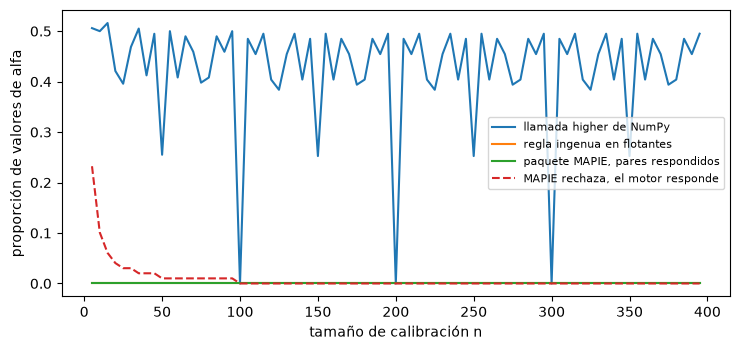

In [6]:
# Para cada tamaño de calibración la proporción de valores de alfa en que cada regla difiere del motor, y la proporción en que MAPIE rechaza
sizes = list(range(5, 400, 5))
share_numpy, share_naive, share_mapie, share_refused = [], [], [], []
for n in sizes:
    s = np.sort(rng.random(n))
    alphas = np.arange(1, 100) / 100
    engine = np.array([conformal.split_conformal_quantile(s, float(a)) for a in alphas])
    numpy_rule = np.array([np.quantile(s, min(1.0, (n + 1) * (1 - a) / n), method="higher") for a in alphas])
    naive = np.array([s[min(math.ceil((n + 1) * (1 - a)), n) - 1] for a in alphas])
    mapie_values = [mapie_quantile(s, float(a)) for a in alphas]
    finite = np.isfinite(engine)
    answered = np.array([v is not None for v in mapie_values])
    both = finite & answered
    mapie_array = np.array([np.nan if v is None else v for v in mapie_values])
    share_numpy.append(float(np.mean(numpy_rule[finite] != engine[finite])))
    share_naive.append(float(np.mean(naive[finite] != engine[finite])))
    share_mapie.append(float(np.mean(mapie_array[both] != engine[both])) if both.any() else float("nan"))
    share_refused.append(float(np.mean(finite & ~answered)))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(sizes, share_numpy, label="llamada higher de NumPy")
ax.plot(sizes, share_naive, label="regla ingenua en flotantes")
ax.plot(sizes, share_mapie, label="paquete MAPIE, pares respondidos")
ax.plot(sizes, share_refused, linestyle="--", label="MAPIE rechaza, el motor responde")
ax.set_xlabel("tamaño de calibración n")
ax.set_ylabel("proporción de valores de alfa")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## Resultados

- **El catálogo del motor contiene 129 pruebas, 13 de validación de aprendizaje automático y 12 de equidad.** El relevamiento del dossier de herramientas abiertas encuentra pruebas de resultados (PiML, mercury-robust, ValidMind), monitoreo sin etiquetas (NannyML, popmon, Evidently), bibliotecas conformes (MAPIE), explicadores (SHAP, InterpretML) y bibliotecas de equidad (fairlearn), bajo licencias de MIT a AGPL; las de AGPL, GPL y BSL se comparan y no se importan. Ninguna informa el tamaño y la potencia de sus pruebas, y ninguna implementa las pruebas de riesgo de crédito del BCE como se especifican, que es la brecha que registra el dossier y que el motor llena para las pruebas de este tema con una nula enunciada, una luz de política y, para dos de ellas, una ley nula corregida (cuadernos 02 y 04).
- **Al tamaño de calibración versionado las reglas coinciden.** Para 1.471 puntajes con $\alpha = 0{,}1$ el motor, el paquete MAPIE, la llamada `higher` de NumPy y la regla ingenua en flotantes devuelven el puntaje de rango 1.325, el rango $k$ de las ventanas de C20 versionadas.
- **A lo largo de la grilla no coinciden en todas partes.** La grilla tiene 39.105 pares $(n, \alpha)$ con $n$ de 5 a 399. En 249 de ellos $n$ es demasiado pequeño para $\alpha$ y el motor no devuelve un cuantil finito; MAPIE también rechaza los 249. En 289 pares MAPIE rechaza y el motor responde, y en los 289 $n$ es menor que $1/\alpha$ o que $1/(1-\alpha)$, la condición que enuncia el propio mensaje de MAPIE. En los 38.567 pares en que ambos responden, el paquete MAPIE devuelve el puntaje del motor en 38.340 y uno distinto en 227 (0,59%). En cada uno de los 227 devuelve exactamente el puntaje de la regla ingenua en flotantes, un estadístico de orden por encima del del motor, un cuantil más conservador. Eso coincide con la trampa de coma flotante del cuaderno 04 (la regla ingenua difiere del motor en 231 pares, 0,6%) y es coherente con que MAPIE tome su rango en coma flotante; la celda no lee el código de MAPIE, así que la causa se infiere de la coincidencia y no se demuestra. La llamada `higher` de NumPy, que una versión anterior de este cuaderno atribuía a MAPIE, difiere del motor en 19.525 pares (49,9%) y no es lo que devuelve el paquete.
- **Las pruebas de dos tasas coinciden con identidades independientes.** Para los cinco contrastes de raza de HMDA el estadístico z combinado al cuadrado es igual al chi-cuadrado de Pearson sin corrección de continuidad hasta los dígitos impresos (por ejemplo 581,966 para el grupo Black contra el White), sus valores p son iguales (1,401e-128), y los valores p de Fisher del motor son iguales a los de SciPy. La diferencia de paridad del motor para dos grupos, 0,15, es igual a la mayor menos la menor tasa de selección, la definición de la diferencia de fairlearn.
- **fairlearn 0.15.0 coincide sobre los conteos de HMDA versionados.** Las tasas de selección de los seis grupos de raza son idénticas hasta los dígitos impresos (diferencia 0). La diferencia de paridad, 0,280754, y la razón de paridad, 0,637966, difieren de las del motor en a lo más 5,6e-17, dentro de la tolerancia de 1e-12; White es el grupo con la tasa más alta, así que la mayor diferencia y la menor razón del motor contra él son las definiciones de fairlearn. Las diferencias de probabilidades igualadas y de igualdad de oportunidad no se reproducen: el documento versionado contiene conteos de aprobaciones, no resultados con etiquetas verdaderas. Ambos documentos se hornearon con riskvalidation 0.8.1.
- **Lo que no se corrió.** NannyML y SHAP no están en el entorno del cuaderno, así que nada aquí reproduce sus resultados; MAPIE y fairlearn sí lo están, con las versiones `mapie==1.5.0` y `fairlearn==0.15.0`, y sus resultados de arriba vienen de los paquetes.

Lo que los resultados no muestran: que el motor sea mejor que alguna de estas herramientas. Muestran lo que cada una enuncia y no enuncia, y dónde puede comprobarse una identidad independiente o una regla de NumPy; la columna de licencias es una lectura del dossier y no asesoría legal.

## Resumen

- Las herramientas abiertas cubren pruebas de resultados, monitoreo sin etiquetas, predicción conforme, explicadores y métricas de equidad bajo licencias de MIT a AGPL; ninguna informa el tamaño y la potencia de sus pruebas, y ninguna implementa las pruebas de riesgo de crédito del BCE como se especifican.
- El motor contiene 13 pruebas de aprendizaje automático y 12 de equidad, cada una con una nula enunciada, una luz de política y la convención que la fija.
- El paquete MAPIE 1.5.0 devuelve el puntaje conforme dividido del motor en 38.340 de los 38.567 pares en que ambos responden; en los otros 227 (0,59%) devuelve el puntaje de la regla ingenua en flotantes, un estadístico de orden por encima, y en otros 289 pares rechaza donde el motor responde. La llamada `higher` de NumPy difiere del motor en el 49,9% de la grilla y no es la regla de MAPIE.
- Las pruebas de dos tasas del motor son iguales al chi-cuadrado de Pearson (sin corrección de continuidad) y a la prueba de Fisher de SciPy, y fairlearn 0.15.0 da las mismas tasas de selección, diferencia de paridad y razón de paridad sobre los conteos de HMDA versionados hasta 5,6e-17.
- NannyML y SHAP no están en el entorno del cuaderno y no se corren; las diferencias de probabilidades igualadas de fairlearn necesitan resultados que los datos versionados no contienen.

**Qué probar después.** El cuaderno 09 mide, con las plantas del propio motor, con qué frecuencia estas pruebas se activan cuando no pasa nada y con qué frecuencia encuentran lo plantado, y muestra las correcciones de las pruebas conforme y de cambio.

## Referencias

- PiML-Toolbox (Apache-2.0), pruebas de resultados WeakSpot, Overfit, Reliability, Robustness y Resilience; Sudjianto et al. (2023), arXiv 2305.04214. https://github.com/SelfExplainML/PiML-Toolbox
- ValidMind library (AGPL-3.0 o licencia comercial): pruebas de validación de datos y modelos y documentación. https://github.com/validmind/validmind-library
- BBVA mercury-robust (Apache-2.0): baterías de pruebas de datos y modelos, chequeos de deriva y de fuga de etiquetas. https://github.com/BBVA/mercury-robust
- ING (2026), probatus, `sample_similarity`: un modelo de semejanza entre dos conjuntos de datos. https://github.com/ing-bank/probatus
- ING popmon (MIT): monitoreo del cambio de población. https://github.com/ing-bank/popmon
- Evidently (Apache-2.0): informes de deriva, calidad de datos y calidad de modelos. https://github.com/evidentlyai/evidently
- NannyML (Apache-2.0), la implementación abierta de CBPE. https://github.com/NannyML/nannyml
- NannyML, cómo funciona la estimación de desempeño basada en confianza (CBPE). https://nannyml.readthedocs.io/en/stable/how_it_works/performance_estimation.html
- fairlearn (MIT), evaluación y mitigación de equidad. https://github.com/fairlearn/fairlearn
- MAPIE (BSD-3-Clause), predicción conforme para scikit-learn. https://github.com/scikit-learn-contrib/MAPIE
- SHAP (MIT), la implementación de referencia de las explicaciones de Shapley. https://github.com/shap/shap
- Angelopoulos, A. N. y Bates, S. (2021), A gentle introduction to conformal prediction and distribution-free uncertainty quantification, arXiv 2107.07511. https://arxiv.org/abs/2107.07511
- Romano, Y., Patterson, E. y Candes, E. J. (2019), Conformalized quantile regression, arXiv 1905.03222. https://arxiv.org/abs/1905.03222
- Barber, R. F., Candes, E. J., Ramdas, A. y Tibshirani, R. J. (2021), Predictive inference with the jackknife+, Annals of Statistics 49(1). https://doi.org/10.1214/20-AOS1965
- Vovk, V. y Petej, I. (2012), Venn-Abers predictors, arXiv 1211.0025. https://arxiv.org/abs/1211.0025
- Hardt, M., Price, E. y Srebro, N. (2016), Equality of opportunity in supervised learning, arXiv 1610.02413. https://arxiv.org/abs/1610.02413
- BCE (2019), Instrucciones para informar los resultados de validación de modelos internos: modelos IRB del Pilar I para riesgo de crédito, Anexo 1 (el AUC y su varianza). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCE (2025), Guía de modelos internos, los párrafos sobre la aleatoriedad del entrenamiento, el sobreajuste, la explicabilidad y la justificación de la complejidad (43, 59, 60, 62, 64 a 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- 29 CFR 1607.4(D), Uniform Guidelines on Employee Selection Procedures: la regla de los cuatro quintos, un referente de empleo. https://www.law.cornell.edu/cfr/text/29/1607.4